# Vehicle Travel Time Prediction

**Machine Learning Fundamentals — Final Practical Assignment**

Authors: Angel Miwa · Miroslava Lange · Maximo Fox — 2026/06/25

This notebook reproduces the full pipeline: streaming and caching the ~2 GB of travel-time
data, exploratory analysis, feature engineering at the monthly-profile granularity, model
comparison with leave-one-month-out cross-validation, the final evaluation on the June-2017
test month, and the generation of the submission file.

The written report (`Vehicle_Travel_Time_Prediction_Report.pdf`) discusses the methodology and
results in detail.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from src import config as C
from src import data_prep as dp
from src import features as F
from src import models as M

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
RNG = C.RANDOM_STATE

## 2. Data

Three sources: link static attributes, the upstream/downstream topology, and the historical
2-minute travel times (three large zipped text files). The heavy scan keeps only the morning
rows [06:00, 09:00) and caches them; if the cache already exists it is reused.

In [2]:
# One-off ~2 GB streaming scan (skipped automatically once the cache exists).
dp.build_cache()

link_info = dp.load_link_info()
topology = dp.load_topology()
print("links:", len(link_info), "| topology rows:", len(topology))
link_info.head()


Scanning gy_link_travel_time_part1.zip ...


  processed 3,000,000 rows (kept 369,796 morning rows)


  processed 6,000,000 rows (kept 733,647 morning rows)


  processed 7,662,384 rows (kept 1,110,293 morning rows)

Scanning gy_link_travel_time_part2.zip ...


  processed 10,662,384 rows (kept 1,474,656 morning rows)


...

  processed 21,367,559 rows (kept 2,927,803 morning rows)


  processed 24,367,559 rows (kept 3,294,443 morning rows)


  processed 25,999,603 rows (kept 3,622,764 morning rows)



Done. Scanned 25,999,603 rows, wrote 3,622,764 morning rows to morning_records.csv.
links: 132 | topology rows: 132


,link_ID,length,width,link_class,link_idx
0,3377906280028510514,48,3,1,0
1,3377906280395510514,59,12,1,1
2,3377906281518510514,22,9,1,2
3,3377906281774510514,64,3,1,3
4,3377906282328510514,27,12,1,4


In [3]:
morning = dp.load_morning()
print("cached morning rows:", f"{len(morning):,}")
morning.head()

cached morning rows: 3,622,764


,link_idx,date,travel_time,minute_of_day
0,8,2016-05-21,10.0,426
1,5,2016-05-21,3.5,536
2,118,2016-05-21,2.0,480
3,116,2016-05-21,2.2,490
4,116,2016-05-21,3.2,530


## 3. Exploratory data analysis

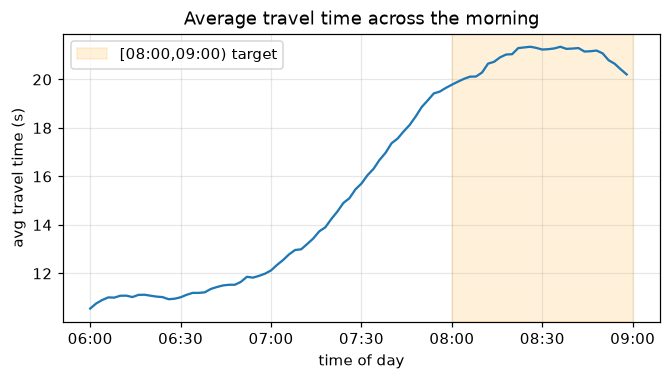

In [4]:
hhmm = lambda m: f"{m//60:02d}:{m%60:02d}"
prof = morning.groupby("minute_of_day")["travel_time"].mean()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(prof.index, prof.values)
ax.axvspan(C.TARGET_START_MIN, C.TARGET_END_MIN, color="orange", alpha=0.15, label="[08:00,09:00) target")
ax.set_xticks(range(360, 541, 30)); ax.set_xticklabels([hhmm(m) for m in range(360, 541, 30)])
ax.set_xlabel("time of day"); ax.set_ylabel("avg travel time (s)")
ax.set_title("Average travel time across the morning"); ax.legend(); plt.show()

link_class values: [1]
width values     : [np.int64(3), np.int64(6), np.int64(9), np.int64(12), np.int64(15)]


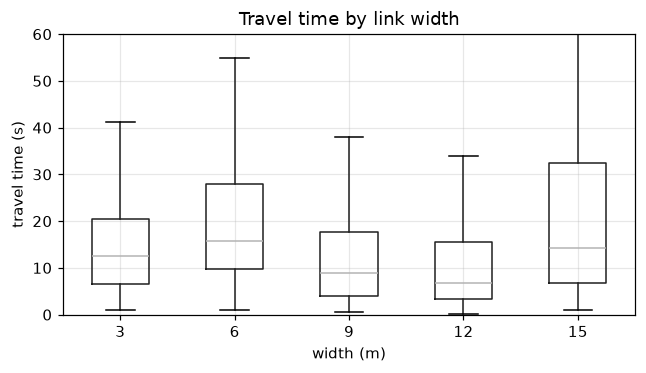

In [5]:
# travel times are positive and right-skewed; link_class is constant; width carries signal
print("link_class values:", link_info["link_class"].unique())
print("width values     :", sorted(link_info["width"].unique()))
mw = morning.merge(link_info[["link_idx", "width"]], on="link_idx")
mw.boxplot("travel_time", by="width", showfliers=False, figsize=(6.5, 3.4))
plt.ylim(0, 60); plt.suptitle(""); plt.title("Travel time by link width")
plt.xlabel("width (m)"); plt.ylabel("travel time (s)"); plt.show()

## 4. Feature engineering

The metric is computed over a monthly-averaged profile (one value per link and slice), so we
build the supervised problem at that granularity: one example per (month, link, target slice).
Each example carries static attributes, calendar context, the month's morning [06:00, 08:00)
signal, and a **leave-one-month-out** historical mean plus a topology-based neighbour mean.

The models do not predict the raw travel time but a **multiplicative correction**
`r = travel_time / historical_mean`; the prediction is recovered as `ŷ = r̂ · historical_mean`.

In [6]:
examples, feat_cols, link_info, aux = F.build_examples()
print("features:", feat_cols)
examples[["link_ID", "month_key", "target_min"] + feat_cols + ["y"]].head()

Built 27,650 (month,link,slice) rows | train=23,750 test=3,900
Labelled training months: [201603, 201604, 201605, 201703, 201704, 201705] | test month: 201706 (June 2016 is morning-only, so it carries no [08:00,09:00) labels)
features: ['length', 'width', 'target_slice_idx', 'month_num', 'year', 'm_feat_mean', 'm_feat_first30', 'm_feat_last30', 'm_feat_last10', 'm_feat_trend', 'm_feat_std', 'm_feat_hour_ago', 'hist_slice_mean', 'neighbor_slice_mean']


,link_ID,month_key,target_min,length,width,target_slice_idx,month_num,year,m_feat_mean,m_feat_first30,m_feat_last30,m_feat_last10,m_feat_trend,m_feat_std,m_feat_hour_ago,hist_slice_mean,neighbor_slice_mean,y
0,3377906280028510514,201603,480,48,3,0,3,2016,5.777211,5.233852,6.582568,7.303002,1.348716,0.788596,4.966667,6.009409,37.385645,9.657143
1,3377906280395510514,201603,480,59,12,0,3,2016,25.632259,13.722150,47.883259,58.379536,34.161110,14.953894,15.200000,45.623584,10.649416,56.437500
2,3377906281518510514,201603,480,22,9,0,3,2016,3.451409,2.864452,4.014168,4.124358,1.149717,0.569847,3.985000,4.163507,26.450833,3.946429
3,3377906281774510514,201603,480,64,3,0,3,2016,8.876143,7.995760,10.403881,11.139419,2.408121,1.357669,7.744444,9.856722,40.853997,10.176471
4,3377906282328510514,201603,480,27,12,0,3,2016,4.362350,3.690907,5.905793,6.725441,2.214886,1.046945,3.721428,6.351115,8.796887,7.728571


## 5. Models and leave-one-month-out cross-validation

We compare a historical-mean baseline, Ridge and Lasso linear regression (with the
regularisation strength chosen by cross-validated MAPE), and a small MLP. Models are compared
with leave-one-month-out CV over the six labelled training months.

In every fold the historical features are **rebuilt from the other five months only**
(`F.with_hist`), so the validation month cannot leak into the training rows' features.
Gradient-boosted trees (outside the course) run through the same protocol as an appendix and
are never eligible for selection.

In [7]:
HIST_FLOOR = 0.1
ratio = lambda df: df["y"].to_numpy(float) / np.clip(df["hist_slice_mean"].to_numpy(float), HIST_FLOOR, None)

def predict_y(est, df):
    h = np.clip(df["hist_slice_mean"].to_numpy(float), HIST_FLOOR, None)
    return M.clip_positive(est.predict(df[feat_cols].to_numpy(float)) * h)

train = examples[examples.role == "train"].copy()
months = sorted(train.month_key.unique())
makers = {"Ridge": M.make_ridge, "Lasso": M.make_lasso, "MLP": M.make_mlp,
          "GBoost (appendix)": M.make_hgb}

rows = {n: [] for n in ["Baseline", *makers]}
for mo in months:
    fold, _ = F.with_hist(aux["raw"], [m for m in months if m != mo], aux)
    fold = fold[fold.role == "train"]
    tr, va = fold[fold.month_key != mo], fold[fold.month_key == mo]
    yva = va["y"].to_numpy(float)
    hva = np.clip(va["hist_slice_mean"].to_numpy(float), HIST_FLOOR, None)
    rows["Baseline"].append(M.mape(yva, hva))
    for name, mk in makers.items():
        est = mk().fit(tr[feat_cols].to_numpy(float), ratio(tr))
        rows[name].append(M.mape(yva, predict_y(est, va)))

cv = pd.DataFrame({n: [np.mean(v)] for n, v in rows.items()}, index=["mean LOMO MAPE (%)"]).T.round(2)
per_month = pd.DataFrame(rows, index=months).T.round(2)   # the 2016 vs 2017 split explains the CV/test gap
display(cv, per_month)

,mean LOMO MAPE (%)
Baseline,21.53
Ridge,18.55
Lasso,18.54
MLP,23.30
GBoost (appendix),14.21


,201603,201604,201605,201703,201704,201705
Baseline,16.99,18.58,16.77,25.55,25.06,26.26
Ridge,18.08,20.92,20.09,17.65,16.93,17.61
Lasso,18.18,20.96,19.83,17.66,17.01,17.62
MLP,28.54,17.91,30.11,20.23,15.24,27.80
GBoost (appendix),14.29,16.04,15.36,14.89,12.32,12.36


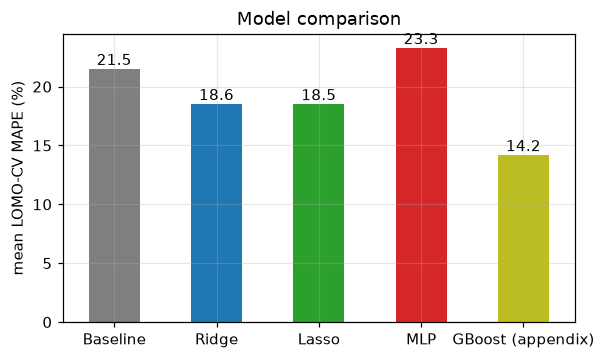

Selected model: Lasso


In [8]:
ax = cv["mean LOMO MAPE (%)"].plot.bar(figsize=(6, 3.4),
        color=["#7f7f7f", "#1f77b4", "#2ca02c", "#d62728", "#bcbd22"], rot=0)
ax.set_ylabel("mean LOMO-CV MAPE (%)"); ax.set_title("Model comparison")
for i, v in enumerate(cv["mean LOMO MAPE (%)"]):
    ax.text(i, v, f"{v:.1f}", ha="center", va="bottom")
plt.show()

best_name = cv.drop(["Baseline", "GBoost (appendix)"])["mean LOMO MAPE (%)"].idxmin()
print("Selected model:", best_name)

## 6. Final evaluation on the June 2017 test month

The selected model is retrained on all six training months and evaluated once against the
actual June-2017 profile (present in the dump, never used for training/selection).

In [9]:
best = makers[best_name]().fit(train[feat_cols].to_numpy(float), ratio(train))
print("chosen hyper-parameters:", getattr(best, "best_params_", "n/a"))

grid_X, meta = F.build_test_grid(examples, link_info, aux)
h = np.clip(grid_X["hist_slice_mean"].to_numpy(float), HIST_FLOOR, None)
meta["pred"]  = M.clip_positive(best.predict(grid_X[feat_cols].to_numpy(float)) * h)
meta["bpred"] = M.clip_positive(grid_X["hist_slice_mean"].to_numpy())

have = meta["actual"].notna() & (meta["actual"] > 0)
gb = makers["GBoost (appendix)"]().fit(train[feat_cols].to_numpy(float), ratio(train))
meta["gbpred"] = M.clip_positive(gb.predict(grid_X[feat_cols].to_numpy(float)) * h)
res = pd.DataFrame({
    "Baseline": M.regression_metrics(meta.loc[have, "actual"], meta.loc[have, "bpred"]),
    best_name:  M.regression_metrics(meta.loc[have, "actual"], meta.loc[have, "pred"]),
    "GBoost (appendix)": M.regression_metrics(meta.loc[have, "actual"], meta.loc[have, "gbpred"]),
}).T.round(3)
res

chosen hyper-parameters: {'model__alpha': 0.001}


,MAPE(%),MAE,RMSE,R2
Baseline,16.990,3.581,7.351,0.879
Lasso,13.619,2.836,5.837,0.924
GBoost (appendix),11.356,2.582,5.698,0.927


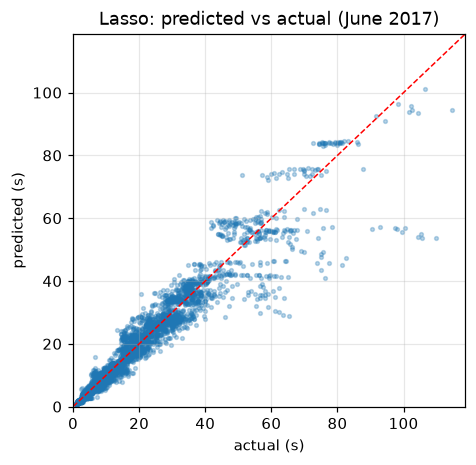

In [10]:
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(meta.loc[have, "actual"], meta.loc[have, "pred"], s=6, alpha=0.3)
lim = float(np.nanpercentile(meta.loc[have, "actual"], 99))
ax.plot([0, lim], [0, lim], "r--", lw=1); ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("actual (s)"); ax.set_ylabel("predicted (s)")
ax.set_title(f"{best_name}: predicted vs actual (June 2017)"); plt.show()

## 7. Submission file

In [11]:
out = meta.sort_values(["link_ID", "target_slice_idx"]).copy()
start = pd.to_datetime("2017-06-01") + pd.to_timedelta(out["target_min"], unit="m")
end = start + pd.to_timedelta(C.SLICE_MINUTES, unit="m")
out["time_interval"] = "[" + start.dt.strftime("%H:%M:%S") + "," + end.dt.strftime("%H:%M:%S") + ")"
submission = out[["link_ID", "time_interval"]].copy()
submission["predicted_travel_time"] = out["pred"].round(4).to_numpy()
submission.to_csv(C.PRED_DIR / "prediction.csv", index=False)
print("rows:", len(submission))
submission.head()

rows: 3960


,link_ID,time_interval,predicted_travel_time
0,3377906280028510514,"[08:00:00,08:02:00)",6.2940
1,3377906280028510514,"[08:02:00,08:04:00)",6.2600
2,3377906280028510514,"[08:04:00,08:06:00)",6.5409
3,3377906280028510514,"[08:06:00,08:08:00)",6.1348
4,3377906280028510514,"[08:08:00,08:10:00)",5.8063


## 8. Conclusion

Using only methods from the course, a **Lasso regression on a multiplicative-correction
target** predicts the June-2017 [08:00, 09:00) profile with a **MAPE of ~13.6%**, beating both
the strong historical-average baseline (~17%) and a neural network. Ridge is statistically tied
with it. The test score is lower than the CV score (~18.5%) because the baseline itself is easier
on June 2017; the per-month table above shows why. Outside the course, gradient-boosted trees
reach ~11.4%. See the report for the full discussion.